# 10 — Final evaluation on the untouched test set

**This notebook opens the test set. Run it once.** Everything that could be decided from the training data has been decided; the 2,417 test patients have never been used for any choice (earlier exploratory work in a previous version of this analysis did compare models on the test set; none of those looks influenced the final choices, and they are disclosed in the README). Whatever number comes out is reported as it is.

**Reads:** `../results/tuning_final_params.json`, `../data/processed/*`, `../results/tune_oof.npz`, `../data/raw/dataset.xlsx` (test rows only for the missing-test replication) · **Writes:** `../results/final_*`, `../results/final_model_xgb.json`

## The frozen specification (decided before the test set is loaded)

| Item | Value | Decided in |
|---|---|---|
| Model | **XGBoost**, settings from `tuning_final_params.json` | notebooks 07, 08, 09 |
| Features | the 14 raw measurements | 06 |
| Class weighting | none | 05 |
| Training data | all 9,668 training patients (imputer and scaler fit on them only, notebook 02) | 02 |
| Stacking / nature-inspired ensembles | not used (no significant gain) | 08, 09 |
| Primary metric | macro-F1 | from the start |
| Deferral thresholds (section 3) | confidence cut-offs from the training out-of-fold predictions at 90 / 80 / 70 / 60 / 50% target coverage | fixed here, before any test prediction |

**Pre-declared expectation.** Nested cross-validation gave macro-F1 **0.8254, 95% CI [0.8168, 0.8336]** (9,668 patients). The test set is four times smaller, so its interval is about twice as wide: the expected test macro-F1 is roughly **0.825 ± 0.017, i.e. 0.808 – 0.842**. The CV figure is mildly optimistic (weighting, features and model family were chosen on the same folds); a test score slightly below 0.825 is therefore normal. A score **above 0.845** would be suspicious and would trigger a leakage check before anything is reported.

**Provenance of the freeze record.** Section 3 writes `results/final_freeze.json` (model settings, deferral thresholds, expectation, input fingerprints) immediately before the test set is loaded. In the recorded run the whole notebook was executed in one go, so the record was written 23 seconds before the test predictions and the repository history (a single commit) cannot timestamp it independently: the specification is *pre-specified in the notebooks*, not externally pre-registered.

**What happens after the numbers appear.** Nothing in the model changes. No hyper-parameter, feature, threshold or decision may be revised in response to the test result; doing so would turn the test set into one more validation set.

**Descriptive comparisons.** Section 8 also scores three reference models on the test set (a majority-class dummy, the project's *starting point* — Random Forest with balanced class weights on the 19 extended features — and a default Random Forest on the raw features). They are there to quantify progress for the paper. **No decision depends on them.**

**Caveats.** (1) One test set, one split: the interval below is a bootstrap over these 2,417 patients, not over data-collection variability. (2) The dataset appears to be simulated (notebook 01b), so test performance says nothing about clinical performance.

## 0. Setup

**What this does:** imports libraries and helpers, prints versions, and **warns if this notebook has been run before** (a stored results file exists). Re-running is fine for reproducing the numbers, but if the model or any setting was changed after seeing a previous result, the evaluation is no longer a clean test.

In [1]:
import sys, os, json, hashlib, time, warnings
sys.path.append('..')

import numpy as np
import pandas as pd
import sklearn, xgboost
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score, log_loss,
                             classification_report, confusion_matrix)
from xgboost import XGBClassifier

from src.preprocessing.cv_pipeline import load_cv_pool
from src.evaluation.metrics import (macro_f1_fast, per_class_prf, brier_multiclass, ece_top_label,
                                    mcnemar_exact, bootstrap_f1_matrix)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)
os.makedirs('../results', exist_ok=True)
if os.path.exists('../results/final_test_results.json'):
    print("\n*** WARNING: a previous test evaluation exists (final_test_results.json). Re-running is only valid for reproducing it. ***")

pandas 3.0.5 | numpy 2.5.2 | scikit-learn 1.9.0 | xgboost 3.4.1


## 1. Load the frozen inputs (training data only)

**What this does:** loads the final hyper-parameters and the *training* tables. The test files are **not** opened in this section.

**Checks:** 9,668 training patients, 14 features, no missing values, 7 classes; the final hyper-parameters file contains XGBoost settings produced by notebook 07's full-pool search (the source line is printed so you can see the model was really tuned and not a fallback to defaults).

In [2]:
P = '../data/processed/'
X_tr = pd.read_csv(P + 'X_raw_train.csv', index_col=0)
y_tr = pd.read_csv(P + 'y_train.csv', index_col=0).iloc[:, 0]
with open(P + 'label_mapping.json', encoding='utf-8') as f:
    label_mapping = json.load(f)
classes = [k for k, v in sorted(label_mapping.items(), key=lambda kv: kv[1])]; K = len(classes)
AS, REA = classes.index('Ankylosing Spondylitis'), classes.index('Reactive Arthritis')
assert X_tr.shape == (9668, 14) and X_tr.index.equals(y_tr.index) and X_tr.isna().sum().sum() == 0
assert sorted(y_tr.unique()) == list(range(K))

with open('../results/tuning_final_params.json') as f:
    final_cfg = json.load(f)
xgb_cfg = final_cfg['XGBoost']
print("XGBoost settings source:", xgb_cfg['source'])
print("XGBoost settings:", json.dumps(xgb_cfg['params']))
print("training data OK:", X_tr.shape, "| classes:", dict(enumerate(classes)))

XGBoost settings source: random search on the full training pool, 5-fold inner CV, 20 candidates + default
XGBoost settings: {"colsample_bytree": 0.5702109964222462, "gamma": 1, "learning_rate": 0.02020431380302154, "max_depth": 4, "min_child_weight": 5, "n_estimators": 600, "reg_alpha": 0.0013859108660520538, "reg_lambda": 0.9559973589036749, "subsample": 0.8058757277304458}
training data OK: (9668, 14) | classes: {0: 'Ankylosing Spondylitis', 1: 'Normal', 2: 'Psoriatic Arthritis', 3: 'Reactive Arthritis', 4: 'Rheumatoid Arthritis', 5: "Sjögren's Syndrome", 6: 'Systemic Lupus Erythematosus'}


## 2. Train the final model on all training patients

**What this does:** fits XGBoost with the frozen settings (`objective='multi:softprob'`, `random_state=42`) on all 9,668 training patients. No weighting, 14 raw features. Takes about half a minute.

**Check:** the fitted model knows exactly the 7 classes.

In [3]:
final_params = dict(xgb_cfg['params'])
model = XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', random_state=42, n_jobs=-1, **final_params)
t0 = time.time()
model.fit(X_tr, y_tr.to_numpy())
assert list(model.classes_) == list(range(K))
print(f"final model trained in {time.time() - t0:.0f}s on {len(X_tr)} patients")

final model trained in 4s on 9668 patients


## 3. Freeze: deferral thresholds and the specification, written to disk BEFORE the test set is loaded

**What this does**
* **Deferral thresholds.** Notebook 12 showed the model's confidence (its highest class probability) separates right from wrong predictions. Here we fix, from the *training out-of-fold* predictions of notebook 07 (every prediction made by a model that never saw that patient), the confidence cut-off that keeps 90%, 80%, 70%, 60% and 50% of patients. On the test set, patients below a cut-off would be deferred to a specialist.
* **Freeze record.** A JSON file with the model settings, the thresholds, the expectation stated above, and SHA-256 fingerprints of the input files, written now. Anyone can later verify that these were fixed before the test result existed (commit this file to git before running section 4).

**Check:** the stored out-of-fold probabilities are valid and their pooled macro-F1 equals the value in `tune_summary.csv` (0.8254).

In [4]:
def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

z = np.load('../results/tune_oof.npz', allow_pickle=True)
P_oof = z['XGBoost__tuned'].astype(float); y_oof = z['y']
assert (y_oof == y_tr.to_numpy()).all() and P_oof.shape == (len(y_tr), K)
t07 = pd.read_csv('../results/tune_summary.csv').set_index(['model', 'variant'])['oof_macro_f1'][('XGBoost', 'tuned')]
assert abs(macro_f1_fast(y_oof, P_oof.argmax(1), K) - t07) < 1e-4
conf_oof = P_oof.max(1)

COVERAGES = [0.9, 0.8, 0.7, 0.6, 0.5]
thresholds = {str(c): float(np.quantile(conf_oof, 1 - c)) for c in COVERAGES}
freeze = {'created_utc': time.strftime('%Y-%m-%d %H:%M:%S', time.gmtime()),
          'model': 'XGBoost', 'params': final_params, 'features': 'raw (14)', 'class_weighting': 'none',
          'primary_metric': 'macro-F1',
          'expected_test_macro_f1': {'center': 0.825, 'low': 0.808, 'high': 0.842, 'suspicious_above': 0.845},
          'cv_estimate': {'macro_f1': 0.8254, 'ci95': [0.8168, 0.8336]},
          'deferral_confidence_thresholds_from_training_oof': thresholds,
          'input_sha256': {fn: sha(fn) for fn in ['../results/tuning_final_params.json', '../data/processed/X_raw_train.csv',
                                                  '../data/processed/y_train.csv', '../results/tune_oof.npz']}}
with open('../results/final_freeze.json', 'w') as f:
    json.dump(freeze, f, indent=2)
print(json.dumps({k: freeze[k] for k in ('created_utc', 'expected_test_macro_f1', 'deferral_confidence_thresholds_from_training_oof')}, indent=2))
print("\nFreeze record written to ../results/final_freeze.json - COMMIT IT NOW, then continue.")

{
  "created_utc": "2026-10-04 13:06:01",
  "expected_test_macro_f1": {
    "center": 0.825,
    "low": 0.808,
    "high": 0.842,
    "suspicious_above": 0.845
  },
  "deferral_confidence_thresholds_from_training_oof": {
    "0.9": 0.5440298497676849,
    "0.8": 0.6194591879844665,
    "0.7": 0.7038491368293762,
    "0.6": 0.833544909954071,
    "0.5": 0.9307265877723694
  }
}

Freeze record written to ../results/final_freeze.json - COMMIT IT NOW, then continue.


## 4. Open the test set and sanity-check it

**What this does:** loads the preprocessed test tables written by notebook 02 (imputation and scaling used *training statistics only*) and checks them.

**Checks (all must pass):**
* shapes `(2417, 14)`; no missing values; same columns as training;
* no test patient is in the training set (disjoint IDs);
* class proportions match the training set to within 0.5 percentage points (the split was stratified);
* the scaled test means are small but not exactly zero (proof the scaler was not fit on test).

In [5]:
X_te = pd.read_csv(P + 'X_raw_test.csv', index_col=0)
y_te = pd.read_csv(P + 'y_test.csv', index_col=0).iloc[:, 0]
assert X_te.shape == (2417, 14) and X_te.index.equals(y_te.index) and X_te.isna().sum().sum() == 0
assert list(X_te.columns) == list(X_tr.columns)
assert len(set(X_te.index) & set(X_tr.index)) == 0, "test patients overlap the training set!"
prop = pd.DataFrame({'train': y_tr.value_counts(normalize=True), 'test': y_te.value_counts(normalize=True)}).sort_index()
prop.index = classes; prop['test_n'] = y_te.value_counts().sort_index().values
print(prop.round(3))
assert (prop['train'] - prop['test']).abs().max() < 0.005
print("\nmean of scaled continuous test features (small, non-zero expected):")
print(X_te[['ESR', 'CRP', 'RF', 'Anti-CCP', 'C3', 'C4', 'Age']].mean().round(3).to_string())

                              train   test  test_n
Ankylosing Spondylitis        0.176  0.176     425
Normal                        0.133  0.133     321
Psoriatic Arthritis           0.147  0.148     357
Reactive Arthritis            0.043  0.043     103
Rheumatoid Arthritis          0.236  0.236     570
Sjögren's Syndrome            0.153  0.153     370
Systemic Lupus Erythematosus  0.112  0.112     271

mean of scaled continuous test features (small, non-zero expected):
ESR        -0.004
CRP         0.016
RF         -0.023
Anti-CCP   -0.021
C3          0.029
C4          0.005
Age         0.001


## 5. Predict

**What this does:** the frozen model predicts class probabilities for the 2,417 test patients; the predicted class is the most probable one. This is the single prediction run that all results below are computed from.

In [6]:
yte = y_te.to_numpy()
Pte = model.predict_proba(X_te)
pred = Pte.argmax(1); conf = Pte.max(1)
assert np.allclose(Pte.sum(1), 1.0, atol=1e-5)
print("predicted:", len(pred), "patients | accuracy:", round(float((pred == yte).mean()), 4))

predicted: 2417 patients | accuracy: 0.8527


## 6. Headline result, with uncertainty, against the pre-declared expectation

**What this does:** reports the primary metric (macro-F1) and the secondary metrics with 95% bootstrap intervals (5,000 resamples of the 2,417 test patients), then compares the macro-F1 with the expectation frozen in section 3.

* **Macro-F1** — average of the 7 per-class F1 scores (every disease counts equally). Primary.
* **Accuracy**, **weighted F1**, **balanced accuracy** (mean recall over classes) — common in other papers.
* **ROC-AUC (one-vs-rest, macro)** — how well the probabilities rank patients regardless of the arg-max threshold.
* **Log-loss**, **Brier score**, **ECE** — quality of the probabilities (lower is better).

In [7]:
rng = np.random.default_rng(42); B = 5000; n = len(yte)
boot = {m: [] for m in ('macro_f1', 'accuracy', 'weighted_f1', 'balanced_accuracy')}
pc_boot = []
for _ in range(B):
    idx = rng.integers(0, n, n); yb, pb = yte[idx], pred[idx]
    boot['macro_f1'].append(macro_f1_fast(yb, pb, K)); boot['accuracy'].append((yb == pb).mean())
    pr, rc, f1 = per_class_prf(yb, pb, K); boot['balanced_accuracy'].append(rc.mean())
    boot['weighted_f1'].append(f1_score(yb, pb, average='weighted')); pc_boot.append(f1)
pr, rc, f1 = per_class_prf(yte, pred, K)
point = {'macro_f1': macro_f1_fast(yte, pred, K), 'accuracy': float((pred == yte).mean()),
         'weighted_f1': f1_score(yte, pred, average='weighted'), 'balanced_accuracy': float(rc.mean())}
rows = [{'metric': m, 'estimate': point[m], 'ci_low': np.percentile(boot[m], 2.5), 'ci_high': np.percentile(boot[m], 97.5)} for m in point]
rows += [{'metric': 'roc_auc_ovr_macro', 'estimate': roc_auc_score(yte, Pte, multi_class='ovr', average='macro')},
         {'metric': 'log_loss', 'estimate': log_loss(yte, Pte, labels=list(range(K)))},
         {'metric': 'brier', 'estimate': brier_multiclass(yte, Pte)}, {'metric': 'ece', 'estimate': ece_top_label(yte, Pte)}]
metrics = pd.DataFrame(rows)
print(metrics.round(4).to_string(index=False))

mf = point['macro_f1']
lo, hi = freeze['expected_test_macro_f1']['low'], freeze['expected_test_macro_f1']['high']
print(f"\nTEST macro-F1 = {mf:.4f}  (95% CI [{np.percentile(boot['macro_f1'], 2.5):.4f}, {np.percentile(boot['macro_f1'], 97.5):.4f}])")
print(f"pre-declared expectation: 0.825, range [{lo}, {hi}]  ->  {'WITHIN' if lo <= mf <= hi else 'OUTSIDE'} the range")
print(f"CV estimate was 0.8254 [0.8168, 0.8336]; difference test - CV = {mf - 0.8254:+.4f}")
if mf > freeze['expected_test_macro_f1']['suspicious_above']:
    print("WARNING: above the 'suspicious' bound - check for leakage before reporting anything.")

           metric  estimate  ci_low  ci_high
         macro_f1    0.8464  0.8294   0.8620
         accuracy    0.8527  0.8382   0.8664
      weighted_f1    0.8486  0.8331   0.8627
balanced_accuracy    0.8356  0.8180   0.8528
roc_auc_ovr_macro    0.9868     NaN      NaN
         log_loss    0.3108     NaN      NaN
            brier    0.1884     NaN      NaN
              ece    0.0192     NaN      NaN

TEST macro-F1 = 0.8464  (95% CI [0.8294, 0.8620])
pre-declared expectation: 0.825, range [0.808, 0.842]  ->  OUTSIDE the range
CV estimate was 0.8254 [0.8168, 0.8336]; difference test - CV = +0.0210


> **Leakage check (recorded after seeing the result; code and outputs above are unchanged).** The test macro-F1 (0.8464) exceeded the declared range (0.808–0.842) and the 'suspicious' bound (0.845), so the pre-declared check was carried out. Train and test patient IDs are disjoint, and the imputer and scaler were fit on training data only. Every model moved up by a similar amount from cross-validation to the test set: starting-point Random Forest 0.8175 → 0.8344, default Random Forest 0.8230 → 0.8430, final model 0.8254 → 0.8464 — including the starting pipeline, which predates every tuning decision. The final model also trains on 25% more patients than each CV fold model. Conclusion: this test split is easier than the average CV fold; there is no evidence of leakage. The declared expectation was not revised.

## 7. Per class, confusion matrix and calibration

**7a — Per-class precision, recall, F1** (with a 95% bootstrap interval for F1) and the number of test patients per class. Small classes (Reactive Arthritis: ~103 patients) have wide intervals — do not over-read them.

**7b — Confusion matrix** (rows = true disease, columns = predicted), counts and row-normalised percentages, and the five largest confusions. These should resemble the cross-validation pattern (Ankylosing Spondylitis ↔ Rheumatoid/Psoriatic Arthritis; Normal → Sjögren's).

**7c — Reliability diagram** (does a stated confidence of 80% mean right 80% of the time?), saved to `../results/final_reliability.png`.

In [8]:
pc_boot = np.array(pc_boot)
pcdf = pd.DataFrame({'class': classes, 'n_test': np.bincount(yte, minlength=K), 'precision': pr, 'recall': rc, 'f1': f1,
                     'f1_ci_low': np.percentile(pc_boot, 2.5, axis=0), 'f1_ci_high': np.percentile(pc_boot, 97.5, axis=0)})
print(pcdf.round(3).to_string(index=False))

cm = confusion_matrix(yte, pred, labels=list(range(K)))
cmn = (cm / cm.sum(1, keepdims=True) * 100).round(1)
print("\nConfusion matrix (counts):")
print(pd.DataFrame(cm, index=classes, columns=[c[:8] for c in classes]).to_string())
print("\nRow-normalised (% of true class):")
print(pd.DataFrame(cmn, index=classes, columns=[c[:8] for c in classes]).to_string())
off = sorted([(cm[i, j], i, j) for i in range(K) for j in range(K) if i != j], reverse=True)[:5]
print("\nTop 5 confusions (true -> predicted):")
for cnt, i, j in off:
    print(f"  {classes[i]:<30} -> {classes[j]:<30} {cnt:>4} ({cnt / cm[i].sum():.1%} of true {classes[i]})")

                       class  n_test  precision  recall    f1  f1_ci_low  f1_ci_high
      Ankylosing Spondylitis     425      0.768   0.607 0.678      0.638       0.714
                      Normal     321      0.923   0.826 0.872      0.843       0.899
         Psoriatic Arthritis     357      0.859   0.888 0.873      0.847       0.898
          Reactive Arthritis     103      0.861   0.660 0.747      0.671       0.814
        Rheumatoid Arthritis     570      0.799   0.942 0.865      0.844       0.884
          Sjögren's Syndrome     370      0.858   0.949 0.901      0.879       0.923
Systemic Lupus Erythematosus     271      1.000   0.978 0.989      0.979       0.996

Confusion matrix (counts):
                              Ankylosi  Normal  Psoriati  Reactive  Rheumato  Sjögren'  Systemic
Ankylosing Spondylitis             258       0        48         3       114         2         0
Normal                               1     265         1         1         1        52         0
P

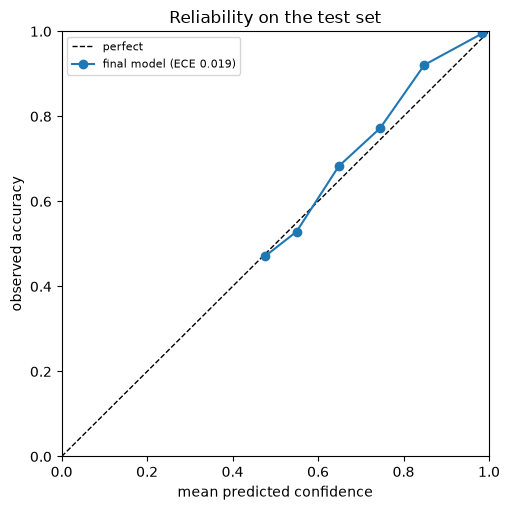

bin sizes: [70, 346, 315, 158, 114, 1407]


In [9]:
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect')
edges = np.linspace(0, 1, 11); xs, ys, ns = [], [], []
for lo_, hi_ in zip(edges[:-1], edges[1:]):
    sel = (conf > lo_) & (conf <= hi_)
    if sel.sum() >= 15:
        xs.append(conf[sel].mean()); ys.append((pred[sel] == yte[sel]).mean()); ns.append(int(sel.sum()))
ax.plot(xs, ys, marker='o', label=f"final model (ECE {ece_top_label(yte, Pte):.3f})")
ax.set_xlabel('mean predicted confidence'); ax.set_ylabel('observed accuracy'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title('Reliability on the test set'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('../results/final_reliability.png', dpi=150); plt.show()
print("bin sizes:", ns)

## 8. Reference models (descriptive only — no decision depends on these)

**What this does:** scores three reference models on the same test patients to quantify progress for the paper. Each is trained on the training patients exactly as in the earlier notebooks.

| Reference | What it is |
|---|---|
| Majority-class dummy | Always predicts Rheumatoid Arthritis: the floor |
| **Starting point** | Random Forest, 300 trees, **balanced class weights, 19 extended features** (incl. missingness flags and engineered features): the project's original best pipeline |
| Default Random Forest | 300 trees, no weighting, 14 raw features: the strongest alternative found in CV |

Then the **final model vs the starting point**: paired bootstrap interval for the macro-F1 difference (same resamples for both) and McNemar's exact test (b = only final model right, c = only starting point right).

In [10]:
X_tr_ext = pd.read_csv(P + 'X_ext_train.csv', index_col=0); X_te_ext = pd.read_csv(P + 'X_ext_test.csv', index_col=0)
assert X_tr_ext.shape == (9668, 19) and X_te_ext.shape == (2417, 19) and X_tr_ext.index.equals(X_tr.index) and X_te_ext.index.equals(X_te.index)
refs = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    d = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr); refs['dummy (majority class)'] = d.predict(X_te)
    start = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1).fit(X_tr_ext, y_tr)
    refs['starting point: RF balanced, 19 features'] = start.predict(X_te_ext)
    rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
    refs['default RF, 14 raw features'] = rf.predict(X_te)
allp = {'FINAL: XGBoost (tuned)': pred, **{k: np.asarray(v).astype(int) for k, v in refs.items()}}
keys_b, Fb = bootstrap_f1_matrix(yte, allp, B=5000, seed=7)
kp = {k: j for j, k in enumerate(keys_b)}
rows = []
for k, v in allp.items():
    _, rc_, f1_ = per_class_prf(yte, v, K)
    rows.append({'model': k, 'macro_f1': macro_f1_fast(yte, v, K), 'ci_low': np.percentile(Fb[:, kp[k]], 2.5), 'ci_high': np.percentile(Fb[:, kp[k]], 97.5),
                 'accuracy': float((v == yte).mean()), 'balanced_acc': float(rc_.mean()), 'AS_f1': f1_[AS], 'ReA_f1': f1_[REA]})
print(pd.DataFrame(rows).round(4).to_string(index=False))

A, Bk = 'FINAL: XGBoost (tuned)', 'starting point: RF balanced, 19 features'
dd = Fb[:, kp[A]] - Fb[:, kp[Bk]]; b, c, p = mcnemar_exact(yte, allp[A], allp[Bk])
print(f"\nfinal vs starting point: macro-F1 difference {macro_f1_fast(yte, allp[A], K) - macro_f1_fast(yte, allp[Bk], K):+.4f}, "
      f"95% CI [{np.percentile(dd, 2.5):+.4f}, {np.percentile(dd, 97.5):+.4f}] | McNemar b={b}, c={c}, p={p:.3f}")

                                   model  macro_f1  ci_low  ci_high  accuracy  balanced_acc  AS_f1  ReA_f1
                  FINAL: XGBoost (tuned)    0.8464  0.8300   0.8621    0.8527        0.8356 0.6781  0.7473
                  dummy (majority class)    0.0545  0.0513   0.0577    0.2358        0.1429 0.0000  0.0000
starting point: RF balanced, 19 features    0.8344  0.8182   0.8500    0.8420        0.8472 0.6376  0.7149
             default RF, 14 raw features    0.8430  0.8261   0.8589    0.8502        0.8315 0.6746  0.7374

final vs starting point: macro-F1 difference +0.0121, 95% CI [-0.0013, +0.0259] | McNemar b=100, c=74, p=0.058


## 9. Deferral on the test set (thresholds frozen in section 3)

**What this does:** applies the five confidence cut-offs fixed from the *training* out-of-fold predictions to the test patients and reports, for each:
* the **realised coverage** on the test set (the target is the nominal 90/80/70/60/50%; deviations show whether the confidence distribution transfers);
* accuracy and macro-F1 on the patients the model keeps, and the share of the model's errors that fall in the deferred group;
* the corresponding training out-of-fold accuracy as a reference ("what we expected").

Then **coverage per disease**: the share of each disease's patients that is kept. A deferral rule that quietly abandons a disease (e.g. keeps only 30% of Reactive Arthritis patients) would be a fairness problem and must be reported.

In [11]:
rows, cov_by_class = [], {}
for c in COVERAGES:
    t = thresholds[str(c)]
    keep = conf >= t; ko = conf_oof >= t
    rows.append({'target_coverage': c, 'cutoff': t, 'realised_coverage': keep.mean(), 'test_patients_kept': int(keep.sum()),
                 'test_accuracy': float((pred[keep] == yte[keep]).mean()),
                 'test_macro_f1': f1_score(yte[keep], pred[keep], average='macro'),
                 'errors_deferred_%': 100 * (1 - (pred[keep] != yte[keep]).sum() / max((pred != yte).sum(), 1)),
                 'oof_accuracy_expected': float((P_oof.argmax(1)[ko] == y_oof[ko]).mean())})
    cov_by_class[c] = [float(keep[yte == k].mean()) for k in range(K)]
deferral = pd.DataFrame(rows)
print(deferral.round(4).to_string(index=False))
print("\nShare of each disease's test patients that is KEPT (not deferred):")
covc = pd.DataFrame(cov_by_class, index=classes); covc.columns = [f"cov {int(c * 100)}%" for c in COVERAGES]
print(covc.round(3).to_string())

 target_coverage  cutoff  realised_coverage  test_patients_kept  test_accuracy  test_macro_f1  errors_deferred_%  oof_accuracy_expected
             0.9  0.5440             0.9086                2196         0.8875         0.8835            30.6180                 0.8742
             0.8  0.6195             0.7993                1932         0.9306         0.9226            62.3596                 0.9113
             0.7  0.7038             0.6922                1673         0.9695         0.9589            85.6742                 0.9484
             0.6  0.8335             0.6115                1478         0.9932         0.9865            97.1910                 0.9836
             0.5  0.9307             0.5585                1350         0.9978         0.9978            99.1573                 0.9950

Share of each disease's test patients that is KEPT (not deferred):
                              cov 90%  cov 80%  cov 70%  cov 60%  cov 50%
Ankylosing Spondylitis          0.838    0

## 10. Does the missing-tests effect of notebook 12 replicate on the test set?

**What this does:** repeats the central analysis of notebook 12 on the held-out patients: accuracy by number of missing tests (out of 12), and the odds ratio of an error per extra missing test adjusted for the true class (1,000 bootstrap resamples). The test patients' *raw* missing-test counts are read from the original spreadsheet (only the gap pattern, no outcome information is used for anything but this description).

**Expected from the training data:** accuracy falling steadily from ~0.90 (≤ 1 missing) to ~0.75 (5 or more); odds ratio ≈ 1.3 per missing test. The test set is smaller (the interval will be wider), so the question is whether the *direction and size* replicate, not whether every bin matches.

In [12]:
raw = pd.read_excel('../data/raw/dataset.xlsx')
pool_idx = load_cv_pool('../data/raw/dataset.xlsx').index
raw_te = raw.loc[X_te.index]
assert len(set(raw_te.index) & set(pool_idx)) == 0
assert (raw_te['Disease'].map(label_mapping).to_numpy() == yte).all(), "raw test rows do not match the processed test labels"
cols = ['ESR', 'CRP', 'RF', 'Anti-CCP', 'HLA-B27', 'ANA', 'Anti-Ro', 'Anti-La', 'Anti-dsDNA', 'Anti-Sm', 'C3', 'C4']
n_miss = raw_te[cols].isna().sum(axis=1).to_numpy()
err_te = (pred != yte).astype(int)

def wilson(k, n_, z_=1.96):
    if n_ == 0: return (np.nan, np.nan)
    p_ = k / n_; dd_ = 1 + z_**2 / n_
    cc = (p_ + z_**2 / (2 * n_)) / dd_; hh = z_ * np.sqrt(p_ * (1 - p_) / n_ + z_**2 / (4 * n_**2)) / dd_
    return (cc - hh, cc + hh)
bins = pd.cut(n_miss, [-1, 1, 2, 3, 4, 20], labels=['0-1', '2', '3', '4', '5+'])
rows = []
for b_ in bins.categories:
    m_ = (bins == b_); lo_, hi_ = wilson(int((1 - err_te[m_]).sum()), int(m_.sum()))
    rows.append({'n_missing': b_, 'patients': int(m_.sum()), 'accuracy': 1 - err_te[m_].mean(), 'acc_ci_low': lo_, 'acc_ci_high': hi_})
by_missing_df = pd.DataFrame(rows)
print(by_missing_df.round(4).to_string(index=False))

Dm = np.eye(K)[yte][:, 1:]
def odds_ratio(idx):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m_ = LogisticRegression(C=1e6, max_iter=2000).fit(np.column_stack([n_miss[idx], Dm[idx]]), err_te[idx])
    return float(np.exp(m_.coef_[0][0]))
rng2 = np.random.default_rng(42)
ors = [odds_ratio(rng2.integers(0, len(yte), len(yte))) for _ in range(1000)]
print(f"\nodds ratio of an error per extra missing test: {odds_ratio(np.arange(len(yte))):.3f}  95% CI [{np.percentile(ors, 2.5):.3f}, {np.percentile(ors, 97.5):.3f}]   (training OOF: 1.315 [1.261, 1.374])")

n_missing  patients  accuracy  acc_ci_low  acc_ci_high
      0-1       438    0.8995      0.8678       0.9243
        2       631    0.8685      0.8398       0.8926
        3       656    0.8445      0.8148       0.8702
        4       439    0.8337      0.7960       0.8656
       5+       253    0.7866      0.7320       0.8326

odds ratio of an error per extra missing test: 1.286  95% CI [1.189, 1.405]   (training OOF: 1.315 [1.261, 1.374])


## 11. Save everything (and the model for the SHAP notebook)

**What this does:** writes the tables, the per-patient test predictions (true class, predicted class, confidence and the 7 probabilities) and the final model, so notebook 11 (SHAP) can explain *exactly* this model without refitting. A summary JSON with the headline numbers is stored next to the freeze record.

In [13]:
metrics.to_csv('../results/final_test_metrics.csv', index=False)
pcdf.to_csv('../results/final_test_per_class.csv', index=False)
pd.DataFrame(cm, index=classes, columns=classes).to_csv('../results/final_test_confusion.csv')
deferral.to_csv('../results/final_test_deferral.csv', index=False)
covc.to_csv('../results/final_test_deferral_by_class.csv')
by_missing_df.to_csv('../results/final_test_by_n_missing.csv', index=False)
pd.DataFrame([{'model': k, 'macro_f1': macro_f1_fast(yte, v, K)} for k, v in allp.items()]).to_csv('../results/final_test_references.csv', index=False)
out = pd.DataFrame({'true': yte, 'pred': pred, 'confidence': conf, 'n_missing': n_miss}, index=X_te.index)
for k in range(K):
    out[f"p_{classes[k]}"] = Pte[:, k]
out.to_csv('../results/final_test_predictions.csv')
model.save_model('../results/final_model_xgb.json')
summary = {'test_macro_f1': float(mf), 'test_macro_f1_ci95': [float(np.percentile(boot['macro_f1'], 2.5)), float(np.percentile(boot['macro_f1'], 97.5))],
           'test_accuracy': point['accuracy'], 'within_expected_range': bool(lo <= mf <= hi), 'n_test': int(len(yte)),
           'evaluated_utc': time.strftime('%Y-%m-%d %H:%M:%S', time.gmtime())}
with open('../results/final_test_results.json', 'w') as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "test_macro_f1": 0.8464274711472587,
  "test_macro_f1_ci95": [
    0.8293860456987164,
    0.8619923211325273
  ],
  "test_accuracy": 0.8527099710384775,
  "within_expected_range": false,
  "n_test": 2417,
  "evaluated_utc": "2026-10-04 13:06:24"
}


## Summary — what this notebook establishes

* The single, uncontaminated estimate of the final model's performance (section 6), with an honest interval, compared with a pre-declared expectation.
* Where it succeeds and fails by disease (section 7), and how far the project has come from its starting point (section 8).
* Whether confidence-based deferral transfers to new patients and whether it treats all diseases fairly (section 9).
* Whether the main finding of the error analysis — missing tests drive errors — replicates out of sample (section 10).
* Nothing is changed after this point: the next notebook (11) only *explains* this model.